In [36]:
# Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


import os

from PIL import Image
from tensorflow.keras.utils import img_to_array
from handspell.data_cleaning import get_labels_images, sort_values_df, drop_unwanted_df

In [2]:
# Assign paths to variables

# Path 1 is the American Sign Language (ASL) Dataset
train_path1 = "../data/raw_data/B02_kaggle_asl_rgb"

# Path 2 to 6 are the 5 folders on ASL Fingerspelling Images (RGB & Depth)
train_path2 = "../data/raw_data/B01_kaggle_asl_rgb_depth/A"
train_path3 = "../data/raw_data/B01_kaggle_asl_rgb_depth/B"
train_path4 = "../data/raw_data/B01_kaggle_asl_rgb_depth/C"
train_path5 = "../data/raw_data/B01_kaggle_asl_rgb_depth/D"
train_path6 = "../data/raw_data/B01_kaggle_asl_rgb_depth/E"

# Test path is the Sign Language Gesture Images Dataset (Only the original data folder not pre-processed)
test_path = "../data/raw_data/B03_kaggle_aslgestures/Gesture Image Data"

In [3]:
print(os.listdir(train_path1))

['.DS_Store', 'r', 'u', '9', '0', '7', 'i', 'n', 'g', '6', 'z', '1', '8', 't', 's', 'a', 'f', 'o', 'h', 'description.md', 'm', 'j', 'c', 'd', 'v', 'q', '4', 'x', '3', 'e', 'b', 'k', 'l', '2', 'y', '5', 'p', 'w']


In [4]:
df_path1 = get_labels_images(train_path1)

df_path2 = get_labels_images(train_path2)
df_path3 = get_labels_images(train_path3)
df_path4 = get_labels_images(train_path4)
df_path5 = get_labels_images(train_path5)
df_path6 = get_labels_images(train_path6)

df_test_path = get_labels_images(test_path)

In [5]:
df_path1.head()

,labels,images
0,R,../data/raw_data/B02_kaggle_asl_rgb/r/hand2_r_...
1,R,../data/raw_data/B02_kaggle_asl_rgb/r/R2837.jpg
2,R,../data/raw_data/B02_kaggle_asl_rgb/r/R2838 co...
3,R,../data/raw_data/B02_kaggle_asl_rgb/r/R2824 co...
4,R,../data/raw_data/B02_kaggle_asl_rgb/r/R2576 co...


In [6]:
dfs = [df_path1, df_path2, df_path3, df_path4, df_path5, df_path6, df_test_path]

sort_values_df(dfs)

In [7]:
df_path2.tail()

,labels,images
12542,Y,../data/raw_data/B01_kaggle_asl_rgb_depth/A/y/...
12543,Y,../data/raw_data/B01_kaggle_asl_rgb_depth/A/y/...
12544,Y,../data/raw_data/B01_kaggle_asl_rgb_depth/A/y/...
12545,Y,../data/raw_data/B01_kaggle_asl_rgb_depth/A/y/...
12546,Y,../data/raw_data/B01_kaggle_asl_rgb_depth/A/y/...


In [8]:
df_path1 = drop_unwanted_df(df_path1)

df_test_path = drop_unwanted_df(df_test_path)

In [9]:
# Merge all the training DataFrames

train_df = pd.merge(df_path2, df_path3, how='outer')
train_df = pd.merge(train_df, df_path4, how='outer')
train_df = pd.merge(train_df, df_path5, how='outer')
train_df = pd.merge(train_df, df_path6, how='outer')

In [10]:
test_df = df_test_path
df_path1['labels'].value_counts()

labels
O    7294
I    6807
L    6494
A    6070
B    6070
C    6070
D    6070
F    6070
G    6070
H    6070
K    5488
N    3968
V    3926
Q    3590
R    3538
U    3244
T    3076
E    3070
M    2924
P    2566
Y    2454
S    2374
X    2330
W    2086
Name: count, dtype: int64

In [11]:
# Balancing df_path1 dataset

temp2 = df_path1.groupby('labels').sample(n=2086, random_state=42).reset_index(drop=True)

In [12]:
temp2['labels'].value_counts()
df_path1 = temp2

In [13]:
train_df = pd.merge(train_df, df_path1, how='outer')

In [19]:
train_df

,labels,images
0,A,../data/raw_data/B01_kaggle_asl_rgb_depth/A/a/...
1,A,../data/raw_data/B01_kaggle_asl_rgb_depth/A/a/...
2,A,../data/raw_data/B01_kaggle_asl_rgb_depth/A/a/...
3,A,../data/raw_data/B01_kaggle_asl_rgb_depth/A/a/...
4,A,../data/raw_data/B01_kaggle_asl_rgb_depth/A/a/...
...,...,...
115833,Y,../data/raw_data/B02_kaggle_asl_rgb/y/hand5_y_...
115834,Y,../data/raw_data/B02_kaggle_asl_rgb/y/hand5_y_...
115835,Y,../data/raw_data/B02_kaggle_asl_rgb/y/hand5_y_...
115836,Y,../data/raw_data/B02_kaggle_asl_rgb/y/hand5_y_...


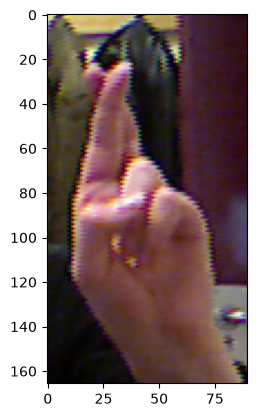

In [32]:
img = Image.open(train_df['images'][78330], mode="r")
plt.imshow(img)